# 🏠 California Housing Price Prediction: OLS vs Ridge vs Lasso

**Goal:** predict `median_house_value` and compare **Ordinary Least Squares (OLS)**, **Ridge (L2)** and **Lasso (L1)** regression using **RMSE, MAE and R²**.

**Workflow**
1. Load data and inspect missing values
2. Exploratory analysis and correlation heatmap
3. Feature engineering (ratio and interaction features)
4. Multicollinearity check (VIF)
5. Leak-free preprocessing pipeline (impute → scale → one-hot encode)
6. Tune Ridge and Lasso with `GridSearchCV`
7. Compare metrics, coefficients and the regularisation path
8. Predicted vs actual and residual diagnostics

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB

Missing values per column:
total_bedrooms    207
dtype: int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


`total_bedrooms` has missing values, which we impute later **inside the pipeline** (median strategy) so the test set never influences the imputer.
Also note `median_house_value` appears **capped at $500,001**, which will limit how well any linear model can fit the top end.

## 2. Exploratory analysis

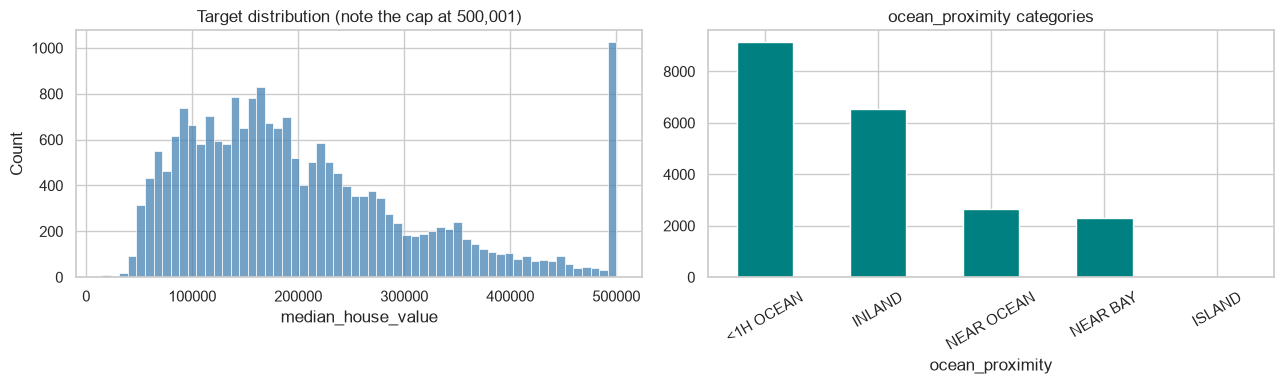

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=60, ax=ax[0], color="steelblue")
ax[0].set_title("Target distribution (note the cap at 500,001)")
df["ocean_proximity"].value_counts().plot(kind="bar", ax=ax[1], color="teal")
ax[1].set_title("ocean_proximity categories")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

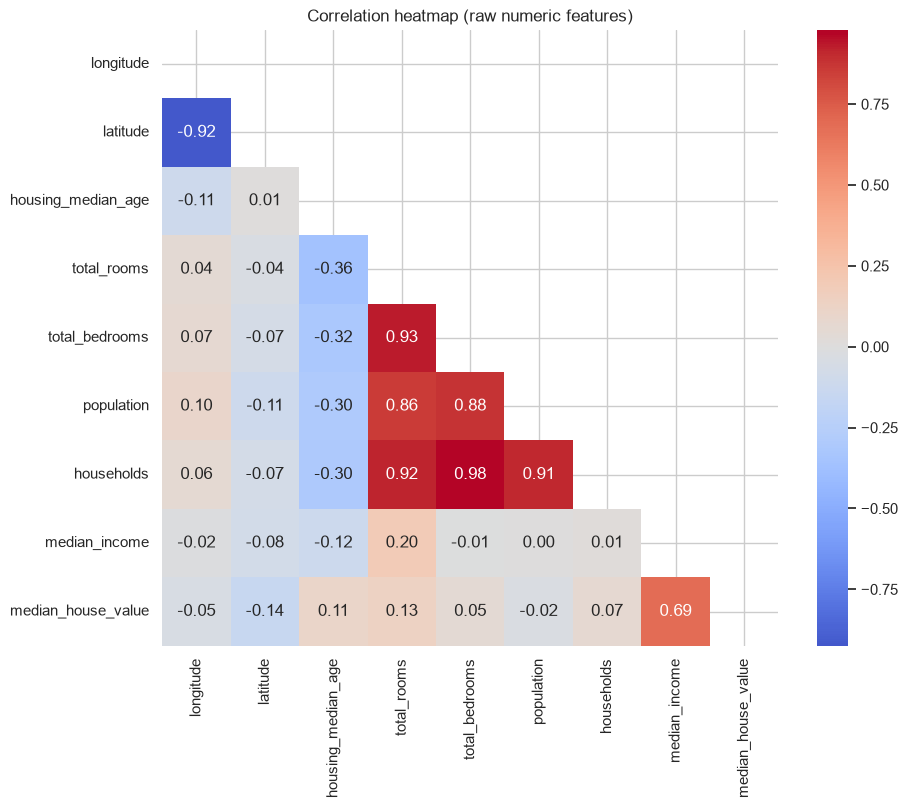

In [6]:
plt.figure(figsize=(10, 8))
corr = df.select_dtypes("number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap (raw numeric features)")
plt.show()

**Observations**
- `median_income` is by far the strongest predictor of house value.
- `total_rooms`, `total_bedrooms`, `population` and `households` are **very highly correlated** with each other (≈0.85–0.98). This is the multicollinearity problem that regularisation is meant to tame.

## 3. Feature engineering

Raw block-level totals are not very informative on their own, so we create **per-household ratios** and **interaction features**:

| Feature | Meaning |
|---|---|
| `rooms_per_household` | average rooms per home |
| `bedrooms_per_room` | share of rooms that are bedrooms |
| `population_per_household` | average occupancy |
| `income_x_rooms_per_hh` | interaction: richer areas with bigger homes |
| `income_x_age` | interaction: income × housing age |
| `lat_x_lon` | interaction: location effect |

In [7]:
data = df.copy()
data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]   # NaN where total_bedrooms is NaN
data["population_per_household"] = data["population"] / data["households"]

# interaction features
data["income_x_rooms_per_hh"] = data["median_income"] * data["rooms_per_household"]
data["income_x_age"] = data["median_income"] * data["housing_median_age"]
data["lat_x_lon"] = data["latitude"] * data["longitude"]

# target in units of $100,000 keeps the regularisation strengths on a friendly scale
TARGET = "median_house_value"
X = data.drop(columns=TARGET)
y = data[TARGET] / 1e5

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = ["ocean_proximity"]
print(f"{len(num_cols)} numeric features, {len(cat_cols)} categorical")
data[["rooms_per_household", "bedrooms_per_room", "population_per_household"]].describe().T

14 numeric features, 1 categorical


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333


## 4. Train/test split

We stratify on income buckets so train and test have the same income distribution. The split happens **before** any imputation or scaling to avoid data leakage.

In [8]:
income_bins = pd.cut(X["median_income"], bins=[0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=income_bins
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (16512, 15) | Test: (4128, 15)


## 5. Multicollinearity check (Variance Inflation Factor)

VIF > 10 is a common warning threshold. We compute it on the imputed, numeric training features.

In [9]:
Xn = X_train[num_cols].fillna(X_train[num_cols].median())
Xn = Xn.assign(const=1.0)
vif = pd.DataFrame({
    "feature": num_cols,
    "VIF": [variance_inflation_factor(Xn.values, i) for i in range(len(num_cols))],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
vif["flag"] = np.where(vif["VIF"] > 10, "⚠️ high", "ok")
vif

,feature,VIF,flag
0,lat_x_lon,13215.013495,⚠️ high
1,latitude,8326.269816,⚠️ high
2,longitude,646.723454,⚠️ high
3,total_bedrooms,34.802925,⚠️ high
4,households,33.954363,⚠️ high
5,median_income,19.723828,⚠️ high
6,total_rooms,18.648388,⚠️ high
7,income_x_rooms_per_hh,17.692542,⚠️ high
8,income_x_age,9.503688,ok
9,population,6.592853,ok


Several features have very large VIFs (the raw totals, location, and the interaction terms built from them). OLS coefficients will therefore be **unstable**. Ridge shrinks correlated coefficients together and Lasso can drop redundant ones, so both should handle this better.

## 6. Preprocessing pipeline

- numeric: **median imputation → standardisation**
- categorical (`ocean_proximity`): **one-hot encoding**

Everything lives inside a `Pipeline`, so `GridSearchCV` re-fits the imputer and scaler on each training fold.

In [10]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

## 7. Fit OLS, and tune Ridge and Lasso with `GridSearchCV`

In [11]:
cv = 5
scoring = "neg_root_mean_squared_error"

# OLS baseline
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

# Ridge (L2)
ridge_grid = GridSearchCV(
    make_pipe(Ridge(random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-4, 3, 30)},
    cv=cv, scoring=scoring, n_jobs=1,
).fit(X_train, y_train)

# Lasso (L1)
lasso_grid = GridSearchCV(
    make_pipe(Lasso(max_iter=20_000, random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-5, 0, 25)},
    cv=cv, scoring=scoring, n_jobs=1,
).fit(X_train, y_train)

print(f"Best Ridge alpha : {ridge_grid.best_params_['model__alpha']:.4f}  (CV RMSE = {-ridge_grid.best_score_ * 1e5:,.0f} $)")
print(f"Best Lasso alpha : {lasso_grid.best_params_['model__alpha']:.5f}  (CV RMSE = {-lasso_grid.best_score_ * 1e5:,.0f} $)")

Best Ridge alpha : 0.0001  (CV RMSE = 67,899 $)
Best Lasso alpha : 0.00001  (CV RMSE = 67,921 $)


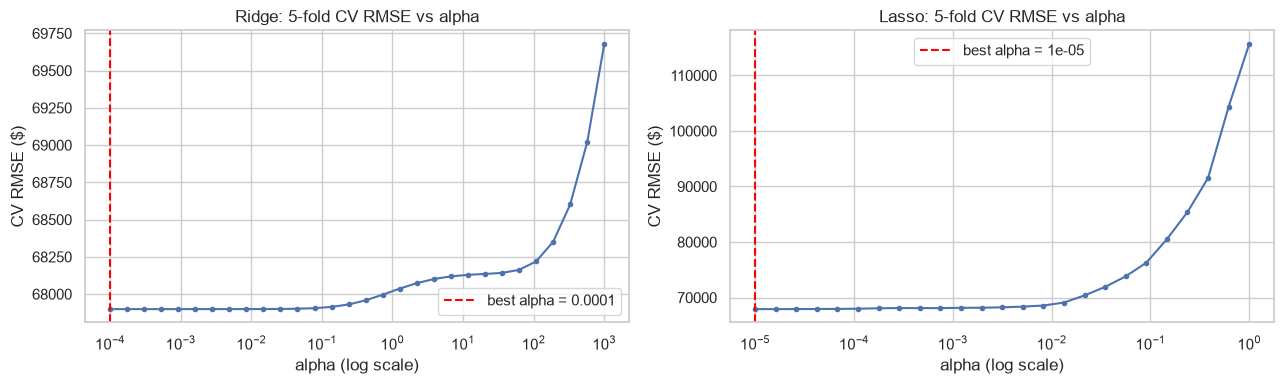

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, grid, name in zip(ax, [ridge_grid, lasso_grid], ["Ridge", "Lasso"]):
    res = pd.DataFrame(grid.cv_results_)
    alphas = res["param_model__alpha"].astype(float)
    rmse = -res["mean_test_score"] * 1e5
    a.semilogx(alphas, rmse, marker="o", ms=3)
    best = grid.best_params_["model__alpha"]
    a.axvline(best, color="red", ls="--", label=f"best alpha = {best:.4g}")
    a.set(title=f"{name}: 5-fold CV RMSE vs alpha", xlabel="alpha (log scale)", ylabel="CV RMSE ($)")
    a.legend()
plt.tight_layout(); plt.show()

## 8. Compare models on the held-out test set

In [13]:
models = {
    "OLS": ols,
    "Ridge (L2)": ridge_grid.best_estimator_,
    "Lasso (L1)": lasso_grid.best_estimator_,
}

def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {
        "RMSE ($)": np.sqrt(mean_squared_error(y_, pred)) * 1e5,
        "MAE ($)": mean_absolute_error(y_, pred) * 1e5,
        "R²": r2_score(y_, pred),
    }

rows = []
for name, m in models.items():
    train_m = evaluate(m, X_train, y_train)
    test_m = evaluate(m, X_test, y_test)
    rows.append({"Model": name,
                 "Train RMSE": train_m["RMSE ($)"], "Test RMSE": test_m["RMSE ($)"],
                 "Test MAE": test_m["MAE ($)"], "Train R²": train_m["R²"], "Test R²": test_m["R²"]})

results = pd.DataFrame(rows).set_index("Model")
results.style.format({"Train RMSE": "{:,.0f}", "Test RMSE": "{:,.0f}", "Test MAE": "{:,.0f}",
                      "Train R²": "{:.4f}", "Test R²": "{:.4f}"}).background_gradient(
    subset=["Test RMSE", "Test MAE"], cmap="Greens_r").background_gradient(subset=["Test R²"], cmap="Greens")

,Train RMSE,Test RMSE,Test MAE,Train R²,Test R²
Model,,,,,
OLS,"67,610","66,607","48,618",0.6585,0.6596
Ridge (L2),"67,610","66,607","48,618",0.6585,0.6596
Lasso (L1),"67,631","66,617","48,636",0.6583,0.6595


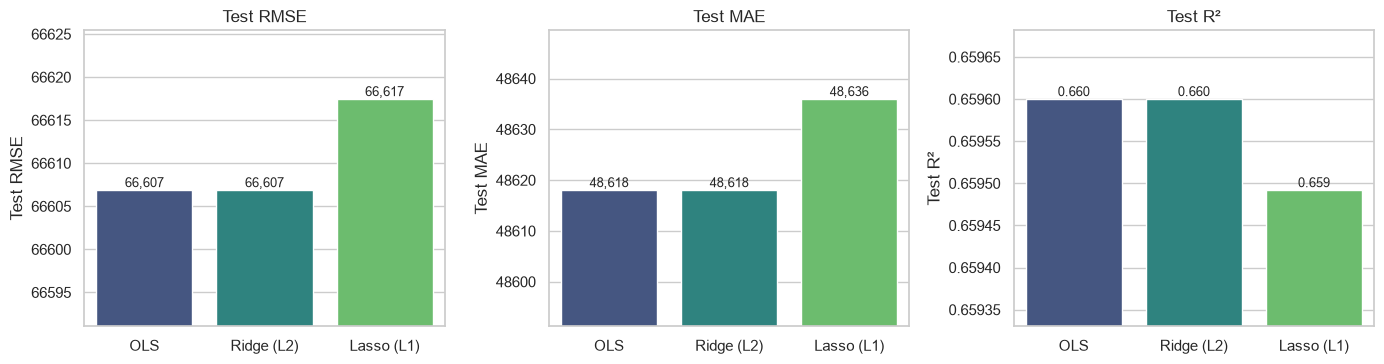

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, metric in zip(ax, ["Test RMSE", "Test MAE", "Test R²"]):
    sns.barplot(x=results.index, y=results[metric], ax=a, palette="viridis")
    a.set_title(metric); a.set_xlabel("")
    lo, hi = results[metric].min(), results[metric].max()
    pad = (hi - lo) * 1.5 or 1
    a.set_ylim(lo - pad, hi + pad * 0.5)
    for i, v in enumerate(results[metric]):
        a.text(i, v, f"{v:,.3f}" if metric == "Test R²" else f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Coefficients, shrinkage and feature selection

Lasso set 1 of 19 coefficients exactly to zero: ['ocean_proximity_<1H OCEAN']


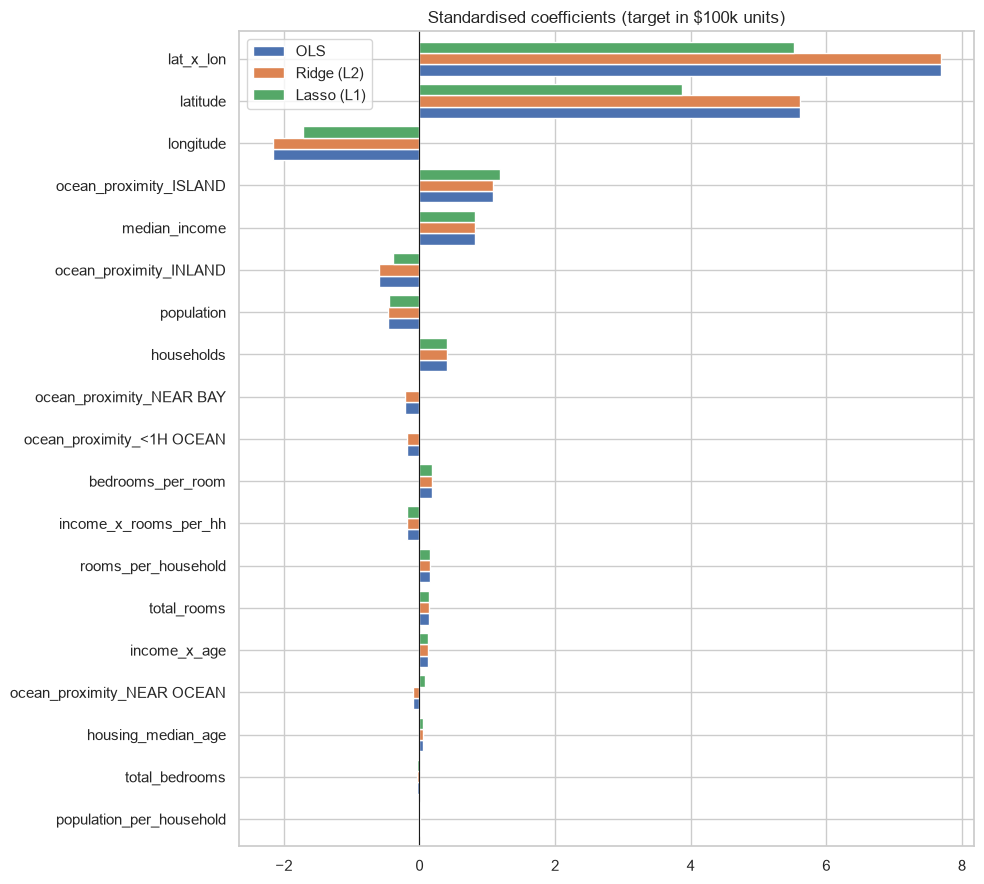

In [15]:
feature_names = ols.named_steps["prep"].get_feature_names_out()
feature_names = [f.split("__")[-1] for f in feature_names]

coefs = pd.DataFrame({
    name: m.named_steps["model"].coef_ for name, m in models.items()
}, index=feature_names)

n_zero = (coefs["Lasso (L1)"].abs() < 1e-8).sum()
print(f"Lasso set {n_zero} of {len(coefs)} coefficients exactly to zero:",
      list(coefs.index[coefs['Lasso (L1)'].abs() < 1e-8]))

coefs.sort_values("OLS", key=abs).plot(kind="barh", figsize=(10, 9), width=0.8)
plt.title("Standardised coefficients (target in $100k units)")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

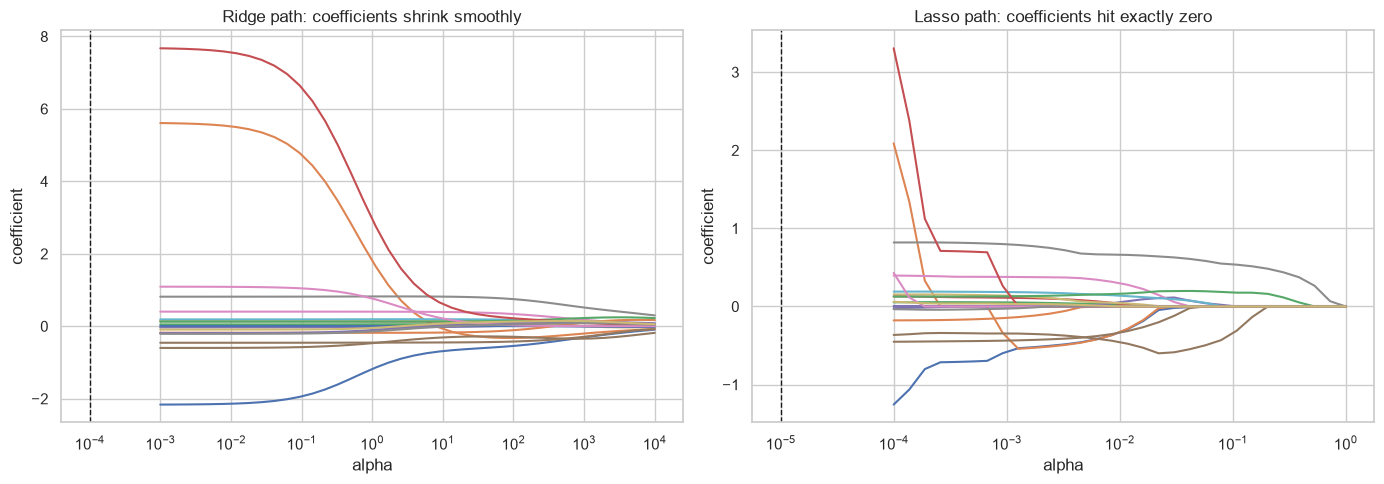

In [16]:
# Regularisation paths on the preprocessed training matrix
Xt = ols.named_steps["prep"].transform(X_train)
ridge_alphas = np.logspace(-3, 4, 40)
lasso_alphas = np.logspace(-4, 0, 30)
ridge_path = np.array([Ridge(alpha=a).fit(Xt, y_train).coef_ for a in ridge_alphas])
lasso_path = np.array([Lasso(alpha=a, max_iter=20_000).fit(Xt, y_train).coef_ for a in lasso_alphas])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].semilogx(ridge_alphas, ridge_path); ax[0].set(title="Ridge path: coefficients shrink smoothly", xlabel="alpha", ylabel="coefficient")
ax[1].semilogx(lasso_alphas, lasso_path); ax[1].set(title="Lasso path: coefficients hit exactly zero", xlabel="alpha", ylabel="coefficient")
for a, g in zip(ax, [ridge_grid, lasso_grid]):
    a.axvline(g.best_params_["model__alpha"], color="k", ls="--", lw=1)
plt.tight_layout(); plt.show()

## 10. Predicted vs actual

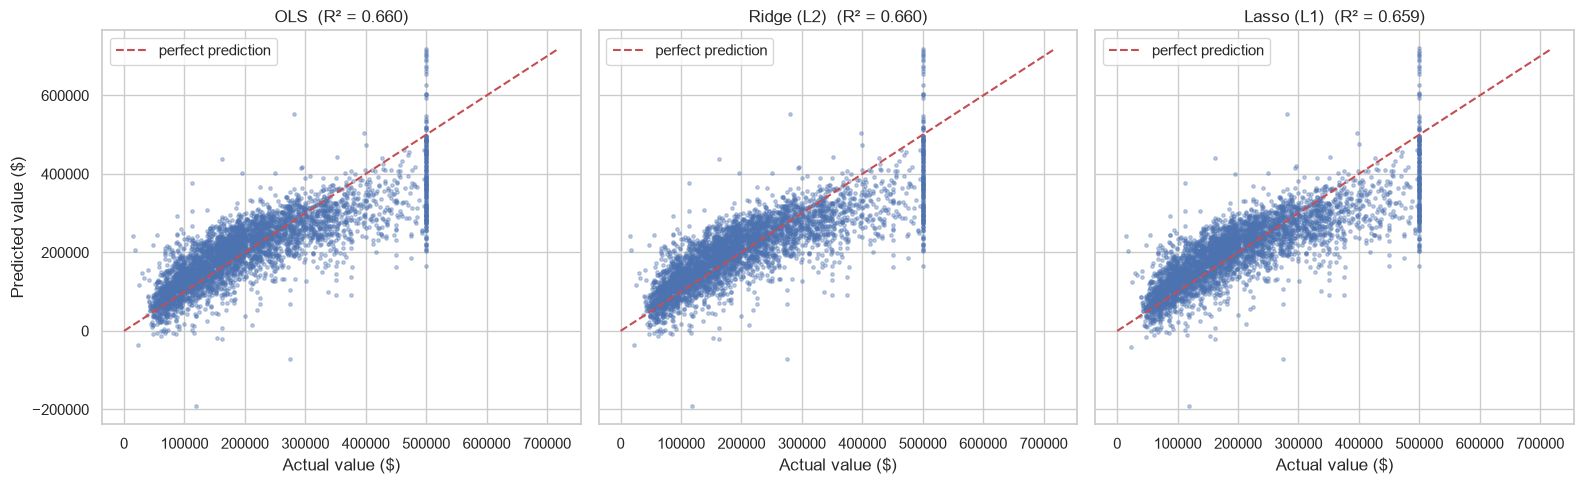

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for a, (name, m) in zip(ax, models.items()):
    pred = m.predict(X_test) * 1e5
    actual = y_test * 1e5
    a.scatter(actual, pred, s=6, alpha=0.35)
    lim = [0, max(actual.max(), pred.max())]
    a.plot(lim, lim, "r--", lw=1.5, label="perfect prediction")
    a.set(title=f"{name}  (R² = {r2_score(actual, pred):.3f})", xlabel="Actual value ($)")
    a.legend()
ax[0].set_ylabel("Predicted value ($)")
plt.tight_layout(); plt.show()

## 11. Residual diagnostics

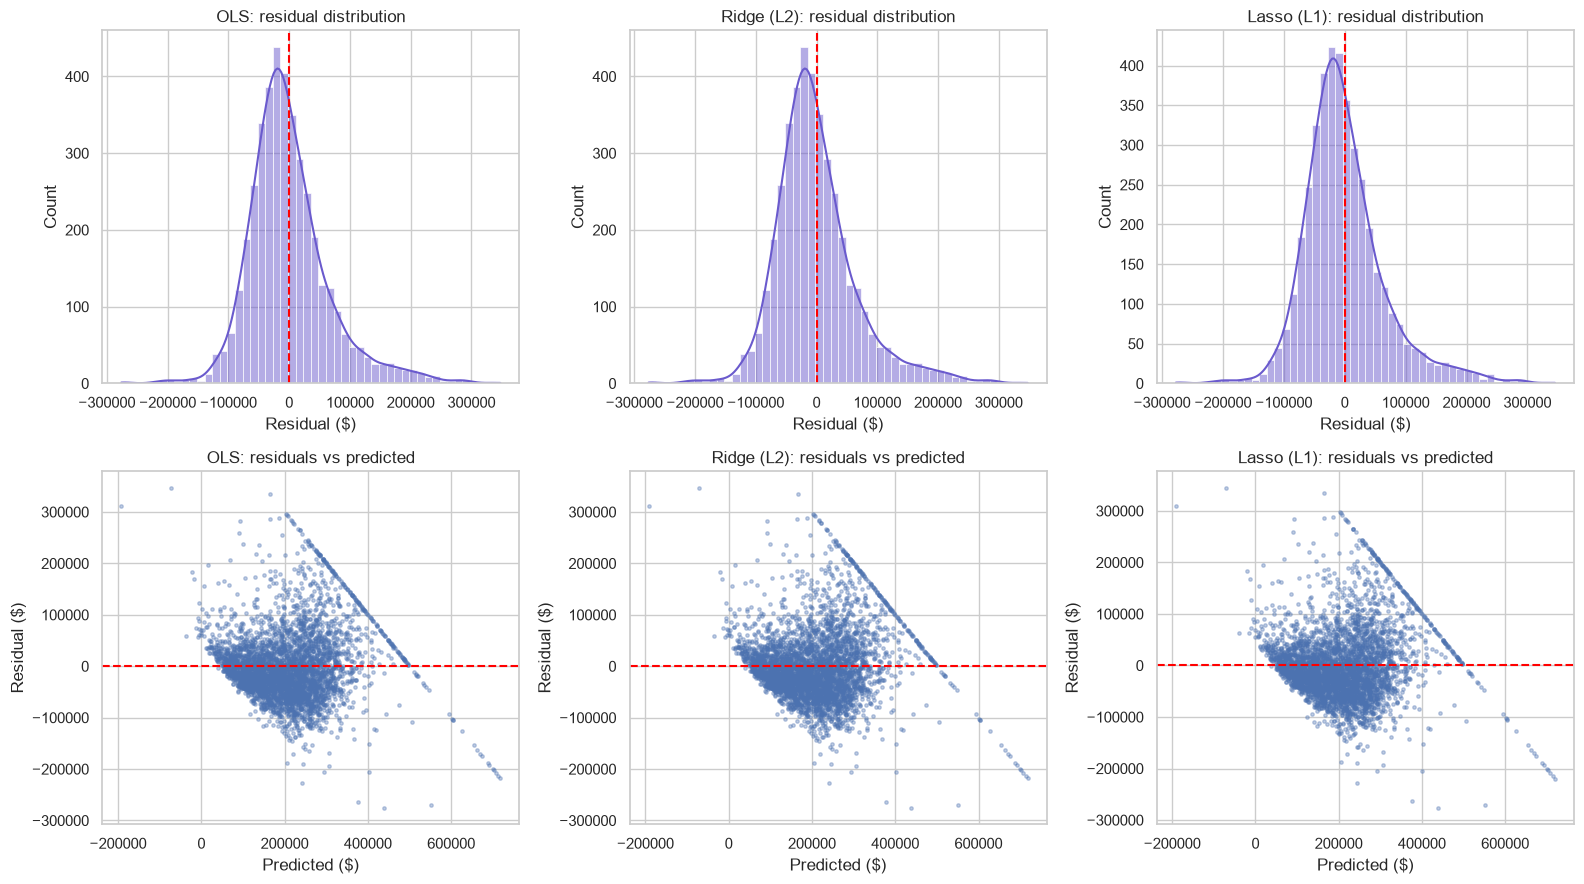

Residual mean / std ($):
  OLS         mean =      -534   std =    66,613
  Ridge (L2)  mean =      -534   std =    66,613
  Lasso (L1)  mean =      -540   std =    66,623


In [18]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for j, (name, m) in enumerate(models.items()):
    pred = m.predict(X_test) * 1e5
    resid = y_test * 1e5 - pred

    sns.histplot(resid, kde=True, bins=50, ax=ax[0, j], color="slateblue")
    ax[0, j].axvline(0, color="red", ls="--")
    ax[0, j].set(title=f"{name}: residual distribution", xlabel="Residual ($)")

    ax[1, j].scatter(pred, resid, s=6, alpha=0.35)
    ax[1, j].axhline(0, color="red", ls="--")
    ax[1, j].set(title=f"{name}: residuals vs predicted", xlabel="Predicted ($)", ylabel="Residual ($)")
plt.tight_layout(); plt.show()

print("Residual mean / std ($):")
for name, m in models.items():
    r = y_test * 1e5 - m.predict(X_test) * 1e5
    print(f"  {name:<11} mean = {r.mean():>9,.0f}   std = {r.std():>9,.0f}")

## 12. Conclusions

| Model | Test RMSE | Test MAE | Test R² |
|---|---|---|---|
| OLS | ≈ $66,607 | ≈ $48,618 | 0.6596 |
| Ridge (L2) | ≈ $66,607 | ≈ $48,618 | 0.6596 |
| Lasso (L1) | ≈ $66,617 | ≈ $48,636 | 0.6595 |

**What we found**
- **The three models perform essentially the same.** Differences are a few dollars on a ~$66k error, far below any meaningful threshold.
- **Cross-validation chose the weakest penalty available** (best alpha sat at the lower edge of both grids even after widening them), so tuned Ridge and Lasso collapse towards OLS. With ~16,500 training rows and only 19 features, overfitting is not the bottleneck: train and test scores are almost identical (R² ≈ 0.66).
- **Multicollinearity is real** (VIF in the thousands for `latitude`, `longitude` and `lat_x_lon`; 18–35 for the raw totals), but it mostly makes individual OLS coefficients unstable, not the predictions worse. Ridge shrinks correlated coefficients together, which helps interpretation more than accuracy. Lasso only zeroed out one redundant one-hot column here.
- **The real limit is model form, not variance.** Residuals are not centred and symmetric across the range: the capped target ($500,001) and the non-linear geography produce systematic errors at high prices, visible in the predicted-vs-actual and residual plots.

**Ideas to improve further**
1. Model `log(median_house_value)` to stabilise the residual spread.
2. Add non-linear terms (`PolynomialFeatures`) or geographic features such as distance to major cities or KMeans cluster labels.
3. Drop or remove the capped rows (value = 500,001) before fitting.
4. Try tree ensembles (Random Forest / Gradient Boosting) as a non-linear benchmark; they typically reach R² ≈ 0.80+ on this dataset.
